# Jour 2 — Analyse des salaires

Consignes : [Octopus](https://octopus.developers.institute/courses/collection/254/course/812/section/1694/chapter/3308), consultées le 29 octobre 2026. Solutions standards uniquement.

Exécuter toutes les cellules dans l’ordre ; installer les dépendances de `Week2/requirements.txt` si nécessaire.

In [1]:
from pathlib import Path
from urllib.parse import quote
import io, zipfile, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid")
# Chaque notebook fonctionne seul, y compris dans Colab ; données publiques du cours.
def course_file(repo, path, member=None):
    cache = Path("data"); cache.mkdir(exist_ok=True)
    destination = cache / (member or Path(path).name)
    if not destination.exists():
        suffix = quote(path)
        response = requests.get(f"https://media.githubusercontent.com/media/devtlv/{repo}/main/{suffix}", timeout=180)
        if response.status_code == 404:
            response = requests.get(f"https://raw.githubusercontent.com/devtlv/{repo}/main/{suffix}", timeout=180)
        response.raise_for_status()
        payload = response.content
        if member:
            with zipfile.ZipFile(io.BytesIO(payload)) as archive:
                matches = [x for x in archive.namelist() if Path(x).name == member and not x.startswith("__MACOSX")]
                if len(matches) != 1: raise ValueError(f"Membre ambigu ou absent : {member}")
                payload = archive.read(matches[0])
        destination.write_bytes(payload)
    return destination


## Chargement et qualité
L’index exporté Unnamed: 0 est retiré des variables analytiques. Des lignes égales après suppression de cet index peuvent correspondre à plusieurs offres : on les quantifie, sans les supprimer arbitrairement en l’absence d’identifiant d’offre.

In [2]:
df=pd.read_csv(course_file("Datasets-DA-Bootcamp-2-","Week 4 - Data Understanding/W4D4 - Data Preprocessing & T/Data Science Job Salary dataset.zip","datascience_salaries.csv"))
display(df.head());display(df.isna().sum().to_frame("manquants"))
df=df.drop(columns=[c for c in df if c.startswith("Unnamed:")])
print("Dimensions",df.shape,"lignes égales",df.duplicated().sum())
df["salary"]=pd.to_numeric(df["salary"],errors="coerce")
assert df["salary"].notna().all() and df["salary"].ge(0).all()
print("Devises",df["salary_currency"].value_counts().to_dict())

,Unnamed: 0,job_title,job_type,experience_level,location,salary_currency,salary
0,0,Data scientist,Full Time,Senior,New York City,USD,149000
1,2,Data scientist,Full Time,Senior,Boston,USD,120000
2,3,Data scientist,Full Time,Senior,London,USD,68000
3,4,Data scientist,Full Time,Senior,Boston,USD,120000
4,5,Data scientist,Full Time,Senior,New York City,USD,149000


,manquants
Unnamed: 0,0
job_title,0
job_type,0
experience_level,0
location,0
salary_currency,0
salary,0


Dimensions (1171, 6) lignes égales 345
Devises {'USD': 1157, 'EUR': 9, 'GBP': 5}


## Normalisation Min-Max
La normalisation demandée porte sur salary. Les montants de devises différentes ne doivent pas être comparés économiquement sans conversion ; les regroupements ci-dessous gardent la devise explicite.

In [3]:
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
df["salary_normalized"]=MinMaxScaler().fit_transform(df[["salary"]]).ravel()
display(df[["salary","salary_normalized"]].describe())
assert np.isclose(df["salary_normalized"].min(),0) and np.isclose(df["salary_normalized"].max(),1)

,salary,salary_normalized
count,1171.000000,1171.000000
mean,64836.037575,0.175940
std,32551.767046,0.164403
min,30000.000000,0.000000
25%,45000.000000,0.075758
50%,63000.000000,0.166667
75%,68000.000000,0.191919
max,228000.000000,1.000000


## Réduction de dimension
Le fichier réel contient surtout des catégories, pas work_year, remote_ratio ou salary_in_usd. Les catégories sont encodées en one-hot. La colonne dérivée salary_normalized est exclue pour ne pas compter deux fois le salaire. Les niveaux catégoriels manquants sont signalés comme Unknown. Les composantes sont descriptives, sans prédiction de salaire.

Variables avant 335 après 2 variance expliquée [0.00850099 0.00762707] cumul 0.016128061039286008


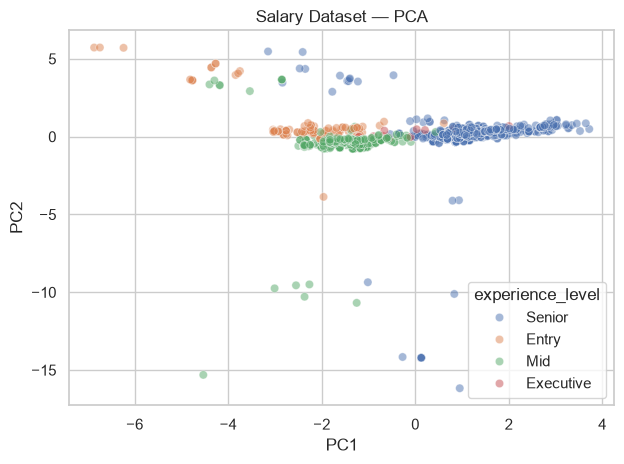

In [4]:
source=df.drop(columns="salary_normalized").copy()
for c in source.select_dtypes(include=["object","string"]):source[c]=source[c].fillna("Unknown")
X=pd.get_dummies(source,dtype=float)
X=SimpleImputer(strategy="median").fit_transform(X)
X=StandardScaler().fit_transform(X)
pca=PCA(n_components=2,random_state=42);coords=pca.fit_transform(X)
print("Variables avant",X.shape[1],"après",coords.shape[1],"variance expliquée",pca.explained_variance_ratio_,"cumul",pca.explained_variance_ratio_.sum())
assert coords.shape==(len(df),2) and np.isfinite(coords).all()
sns.scatterplot(x=coords[:,0],y=coords[:,1],hue=df["experience_level"],alpha=.5)
plt.xlabel("PC1");plt.ylabel("PC2");plt.title("Salary Dataset — PCA");plt.tight_layout();plt.show()

## Agrégation par expérience

In [5]:
summary=df.groupby(["salary_currency","experience_level"],dropna=False)["salary"].agg(["count","mean","median"]).round(2)
display(summary)
for currency,part in df.groupby("salary_currency"):
    means=part.groupby("experience_level")["salary"].mean().sort_values()
    print(currency,"moyenne la plus élevée :",means.index[-1],f"{means.iloc[-1]:,.2f}")
Path("results").mkdir(exist_ok=True)
summary.to_csv("results/salary_by_experience.csv")

count      mean   median
salary_currency experience_level                          
EUR             Mid                   2  54000.00  54000.0
                Senior                7  45285.71  36000.0
GBP             Mid                   4  48750.00  45000.0
                Senior                1  57000.00  57000.0
USD             Entry               126  36111.11  30000.0
                Executive            13  76076.92  46000.0
                Mid                 299  51812.71  51000.0
                Senior              719  75403.34  68000.0

EUR moyenne la plus élevée : Mid 54,000.00
GBP moyenne la plus élevée : Senior 57,000.00
USD moyenne la plus élevée : Executive 76,076.92


### Interprétation
La moyenne reflète les valeurs extrêmes davantage que la médiane. Comparer niveaux d’expérience dans une même devise, en tenant compte des effectifs et du mélange de métiers et de villes. La PCA perd une partie de l’information : son taux de variance expliqué est affiché, elle ne prouve pas l’existence de groupes naturels. Les offres observées ne constituent pas un échantillon représentatif de tous les salaires.